# 01 · Understanding the Data

**The question:** What is inside the two UNSW-NB15 files, and is the data clean enough to work with?

| | |
|---|---|
| **Input** | `data/raw/UNSW_NB15_training-set.csv` and `data/raw/UNSW_NB15_testing-set.csv` |
| **What we do** | Look at every column, check data quality, study the classes we want to predict, and note anything risky |
| **Output** | Summary tables in `results/tables/v3/`, figures in `results/figures/v3/`, and a list of issues for Notebook 02 |

### Where this fits in the project

Our project is about **detecting botnet and other network attacks**. The reference paper (Mohan et al., *Scientific Reports*) uses
network-flow measurements together with DNS-query measurements and a deep-learning model.

We work with **UNSW-NB15**. Each row describes one **network flow**: one conversation between two computers, summarised as numbers
such as bytes sent, packets sent, duration and so on. Each flow is labelled **Normal** or as one of **nine attack types**.

This first notebook only *looks*. We do not change, clean or model anything here.

**Project path:** 01 Understand data → 02 Data problems and fair splits → 03 EDA and preprocessing → 04 Feature engineering → 05 Feature selection → 06 Baseline models

## 1. Setup

We load the usual libraries and a small helper file (`src/notebook_helpers.py`) that only holds folder paths and save functions.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.notebook_helpers import (ROOT, TRAIN_CSV, TEST_CSV, RAW_SHA256, TARGETS, CATEGORICAL, CLASSES,
                                  sha256, save_table, save_figure, setup_style)
setup_style()
print('Project folder:', ROOT)

Project folder: D:\projects\Botnet attack detection


## 2. Load the two files

The dataset comes already split into a **training file** and a **testing file**. We keep them separate from the very start.
The test file is our final exam: we look at it here only to describe it, and we will never use it to make choices.

First we confirm that the files are exactly the ones we received, using a fingerprint (SHA-256 hash). If even one byte changes, the fingerprint changes.

In [2]:
fingerprints_before = {'train': sha256(TRAIN_CSV), 'test': sha256(TEST_CSV)}
for split, value in fingerprints_before.items():
    status = 'OK - unchanged' if value == RAW_SHA256[split] else 'DIFFERENT from the recorded fingerprint!'
    print(f'{split:5s} {value[:16]}...  {status}')
assert fingerprints_before == RAW_SHA256

train = pd.read_csv(TRAIN_CSV, low_memory=False)
test = pd.read_csv(TEST_CSV, low_memory=False)

display(pd.DataFrame({'rows': [len(train), len(test)], 'columns': [train.shape[1], test.shape[1]]},
                     index=['training file', 'testing file']))

train bec7dd5ec88dc2a0...  OK - unchanged
test  734fe6642edf758f...  OK - unchanged


,rows,columns
training file,175341,45
testing file,82332,45


## 3. A first look at the rows

Each row is one network flow. Below are three flows from the training file.

In [3]:
display(train.head(3))

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.1215,tcp,-,FIN,6,4,258,172,74.0875,252,254,"14,158.9424","8,495.3652",0,0,24.2956,8.3750,30.1775,11.8306,255,621772692,2202533631,255,0.0000,0.0000,0.0000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.6499,tcp,-,FIN,14,38,734,42014,78.4734,62,252,"8,395.1123","503,571.3125",2,17,49.9150,15.4329,61.4269,"1,387.7783",255,1417884146,3077387971,255,0.0000,0.0000,0.0000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.6231,tcp,-,FIN,8,16,364,13186,14.1702,62,252,"1,572.2719","60,929.2305",1,6,231.8756,102.7372,"17,179.5869","11,420.9262",255,2116150707,2963114973,255,0.1119,0.0615,0.0504,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0


**What we see:** 45 columns. Three of them are special:

- `id` – just a row number. It says nothing about the traffic.
- `label` – **0 = Normal, 1 = Attack**.
- `attack_cat` – the attack type (or `Normal`).

The other **42 columns** are the measurements we can use to make a prediction. We call them **predictors**.

## 4. What each column means

To work sensibly with a column we need to know what it measures. The table groups the 42 predictors by topic,
using the descriptions from the dataset creators (Moustafa & Slay, 2015). "src" means the side that started the flow, "dst" the other side.

In [4]:
column_meaning = {
    # basic information
    'proto': ('Basic flow information', 'Transport protocol (tcp, udp, ...)'),
    'service': ('Basic flow information', "Application service (http, dns, ftp, ...); '-' means not identified"),
    'state': ('Basic flow information', 'Connection state at the end (FIN, CON, INT, ...)'),
    'dur': ('Basic flow information', 'How long the flow lasted (seconds)'),
    # size
    'spkts': ('Size of the flow', 'Packets sent src -> dst'),
    'dpkts': ('Size of the flow', 'Packets sent dst -> src'),
    'sbytes': ('Size of the flow', 'Bytes sent src -> dst'),
    'dbytes': ('Size of the flow', 'Bytes sent dst -> src'),
    'smean': ('Size of the flow', 'Average packet size src -> dst (bytes)'),
    'dmean': ('Size of the flow', 'Average packet size dst -> src (bytes)'),
    # speed
    'rate': ('Speed and load', 'Packets per second'),
    'sload': ('Speed and load', 'Bits per second src -> dst'),
    'dload': ('Speed and load', 'Bits per second dst -> src'),
    'sloss': ('Speed and load', 'Packets lost or resent by src'),
    'dloss': ('Speed and load', 'Packets lost or resent by dst'),
    # timing
    'sinpkt': ('Timing', 'Average time between packets from src (ms)'),
    'dinpkt': ('Timing', 'Average time between packets from dst (ms)'),
    'sjit': ('Timing', 'Variation of packet timing from src (jitter, ms)'),
    'djit': ('Timing', 'Variation of packet timing from dst (jitter, ms)'),
    'tcprtt': ('Timing', 'TCP setup round-trip time (synack + ackdat)'),
    'synack': ('Timing', 'Time between SYN and SYN-ACK'),
    'ackdat': ('Timing', 'Time between SYN-ACK and ACK'),
    # header values
    'sttl': ('Packet header values', 'Time-to-live value src -> dst'),
    'dttl': ('Packet header values', 'Time-to-live value dst -> src'),
    'swin': ('Packet header values', 'TCP window size of src'),
    'dwin': ('Packet header values', 'TCP window size of dst'),
    'stcpb': ('Packet header values', 'TCP starting sequence number of src'),
    'dtcpb': ('Packet header values', 'TCP starting sequence number of dst'),
    'is_sm_ips_ports': ('Packet header values', '1 if source and destination address and port are the same'),
    # content
    'trans_depth': ('Web and FTP content', 'Position of the flow inside an HTTP request/response chain'),
    'response_body_len': ('Web and FTP content', 'Size of the HTTP response body'),
    'ct_flw_http_mthd': ('Web and FTP content', 'Number of HTTP GET/POST methods in the flow'),
    'is_ftp_login': ('Web and FTP content', '1 if an FTP login with user and password happened'),
    'ct_ftp_cmd': ('Web and FTP content', 'Number of FTP commands in the session'),
    # context counters
    'ct_srv_src': ('Counts over recent flows', 'Recent flows with the same service and source address'),
    'ct_srv_dst': ('Counts over recent flows', 'Recent flows with the same service and destination address'),
    'ct_dst_ltm': ('Counts over recent flows', 'Recent flows with the same destination address'),
    'ct_src_ltm': ('Counts over recent flows', 'Recent flows with the same source address'),
    'ct_src_dport_ltm': ('Counts over recent flows', 'Recent flows with the same source address and destination port'),
    'ct_dst_sport_ltm': ('Counts over recent flows', 'Recent flows with the same destination address and source port'),
    'ct_dst_src_ltm': ('Counts over recent flows', 'Recent flows with the same source and destination address'),
    'ct_state_ttl': ('Counts over recent flows', 'Count based on state and time-to-live ranges'),
}

predictors = [c for c in train.columns if c not in TARGETS]
assert set(predictors) == set(column_meaning), 'every predictor needs a description'

dictionary = pd.DataFrame([(c, *column_meaning[c], str(train[c].dtype), train[c].nunique()) for c in predictors],
                          columns=['column', 'topic', 'meaning', 'type', 'distinct values in train'])
save_table(dictionary, '01_column_dictionary')
display(dictionary)
display(dictionary.topic.value_counts().rename('number of columns').to_frame())

,column,topic,meaning,type,distinct values in train
0,dur,Basic flow information,How long the flow lasted (seconds),float64,74039
1,proto,Basic flow information,"Transport protocol (tcp, udp, ...)",str,133
2,service,Basic flow information,"Application service (http, dns, ftp, ...); '-'...",str,13
3,state,Basic flow information,"Connection state at the end (FIN, CON, INT, ...)",str,9
4,spkts,Size of the flow,Packets sent src -> dst,int64,480
5,dpkts,Size of the flow,Packets sent dst -> src,int64,443
6,sbytes,Size of the flow,Bytes sent src -> dst,int64,7214
7,dbytes,Size of the flow,Bytes sent dst -> src,int64,6660
8,rate,Speed and load,Packets per second,float64,76991
9,sttl,Packet header values,Time-to-live value src -> dst,int64,11


,number of columns
topic,
Counts over recent flows,8
Packet header values,7
Timing,7
Size of the flow,6
Speed and load,5
Web and FTP content,5
Basic flow information,4


**What we see:** The 42 predictors describe each flow from seven angles. 39 are numbers and 3 are text (`proto`, `service`, `state`).

The last group ("Counts over recent flows") is different from the rest: these values are counted over the **previous ~100 connections**,
so they carry some information about the surrounding traffic, not only the flow itself.

## 5. Is the data clean?

We check the basic problems that can break an analysis: missing values, infinite values, negative numbers where they make no sense,
columns that never change, and whether both files have the same columns.

In [5]:
numeric = [c for c in predictors if c not in CATEGORICAL]

def quality(frame, name):
    num = frame[numeric]
    return {'file': name,
            'missing cells': int(frame.isna().sum().sum()),
            'infinite values': int(np.isinf(num.to_numpy()).sum()),
            'negative numbers': int((num < 0).sum().sum()),
            'columns with one value only': int((frame[predictors].nunique() == 1).sum()),
            'fully identical rows (incl. id)': int(frame.duplicated().sum())}

quality_table = pd.DataFrame([quality(train, 'training'), quality(test, 'testing')]).set_index('file')
save_table(quality_table, '01_data_quality', index=True)
display(quality_table)

print('Same columns in the same order:', list(train.columns) == list(test.columns))
print('Same data types:', (train.dtypes == test.dtypes).all())

,missing cells,infinite values,negative numbers,columns with one value only,fully identical rows (incl. id)
file,,,,,
training,0,0,0,0,0
testing,0,0,0,0,0


Same columns in the same order: True
Same data types: True


**What we see:** The files are technically clean: no missing cells, no infinite values, no negative numbers, no constant columns,
and both files share the same columns and types.

"No fully identical rows" is only true because every row has its own `id`. Once we ignore `id`, many rows repeat (section 10).

## 6. What are we trying to predict?

There are two possible targets:

- **Binary:** Normal vs Attack (`label`).
- **Multiclass:** which of the 10 categories (`attack_cat`): Normal plus 9 attack types.

The multiclass task is the main one because it is harder and more informative. Binary results can always be derived from it
(every non-Normal prediction counts as "Attack").

In [6]:
counts = pd.DataFrame({'train rows': train.attack_cat.value_counts(),
                       'test rows': test.attack_cat.value_counts()}).reindex(CLASSES)
counts['train %'] = counts['train rows'] / len(train) * 100
counts['test %'] = counts['test rows'] / len(test) * 100
counts = counts.sort_values('train rows', ascending=False)
save_table(counts, '01_class_counts', index=True)
display(counts)

assert (train.label == (train.attack_cat != 'Normal')).all() and (test.label == (test.attack_cat != 'Normal')).all()
print('label is always 1 exactly when attack_cat is not Normal -> the two targets agree everywhere.')

,train rows,test rows,train %,test %
attack_cat,,,,
Normal,56000,37000,31.9378,44.9400
Generic,40000,18871,22.8127,22.9206
Exploits,33393,11132,19.0446,13.5209
Fuzzers,18184,6062,10.3706,7.3629
DoS,12264,4089,6.9944,4.9665
Reconnaissance,10491,3496,5.9832,4.2462
Analysis,2000,677,1.1406,0.8223
Backdoor,1746,583,0.9958,0.7081
Shellcode,1133,378,0.6462,0.4591


label is always 1 exactly when attack_cat is not Normal -> the two targets agree everywhere.


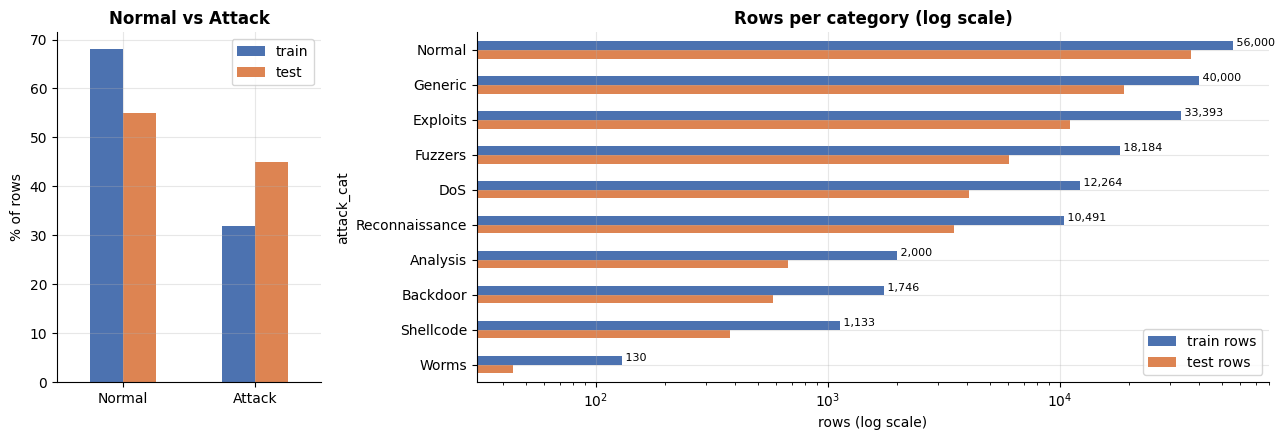

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1, 3]})
binary = pd.DataFrame({'train': train.label.value_counts(normalize=True), 'test': test.label.value_counts(normalize=True)}) * 100
binary.index = ['Normal', 'Attack']
binary.plot.bar(ax=axes[0], rot=0, color=['#4C72B0', '#DD8452'])
axes[0].set(title='Normal vs Attack', ylabel='% of rows')

counts[['train rows', 'test rows']].plot.barh(ax=axes[1], color=['#4C72B0', '#DD8452'], logx=True)
axes[1].invert_yaxis()
axes[1].set(title='Rows per category (log scale)', xlabel='rows (log scale)')
for i, v in enumerate(counts['train rows']):
    axes[1].text(v, i - 0.2, f' {v:,}', va='center', fontsize=8)
plt.tight_layout(); save_figure(fig, '01_class_distribution'); plt.show()

In [8]:
imbalance = counts['train rows'].max() / counts['train rows'].min()
print(f'Largest class / smallest class in training: {imbalance:,.0f} to 1')
print(f"Worms: {counts.loc['Worms', 'train rows']} training rows and {counts.loc['Worms', 'test rows']} test rows")

Largest class / smallest class in training: 431 to 1
Worms: 130 training rows and 44 test rows


**What we see:**

- The classes are **very unbalanced**. Normal and Generic have tens of thousands of rows; **Worms has only 130** training rows (431 to 1).
- The share of attacks is different in the two files (about 68% in training and 55% in testing).

**Why it matters:** a model can reach high *accuracy* by getting the big classes right and ignoring the small ones.
So we will judge models mainly by **macro F1**, which gives every class the same weight, and we will always look at the rare classes separately.

## 7. The three text columns

`proto`, `service` and `state` contain words, not numbers. Models need them turned into numbers later (Notebook 03).
Here we look at which values occur and whether the two files use the same values.

In [9]:
for col in CATEGORICAL:
    tr, te = train[col].value_counts(), test[col].value_counts()
    print(f"{col}: {len(tr)} values in train, {len(te)} in test | most common in train: "
          + ', '.join(f'{k} ({v:,})' for k, v in tr.head(5).items()))
    only_train, only_test = sorted(set(tr.index) - set(te.index)), sorted(set(te.index) - set(tr.index))
    print(f'   only in train: {only_train[:10]}{" ..." if len(only_train) > 10 else ""}   only in test: {only_test}')

dash = pd.DataFrame({'rows with service = "-"': [(train.service == '-').sum(), (test.service == '-').sum()]},
                    index=['training', 'testing'])
dash['share %'] = dash.iloc[:, 0] / [len(train), len(test)] * 100
display(dash)

proto: 133 values in train, 131 in test | most common in train: tcp (79,946), udp (63,283), unas (12,084), arp (2,859), ospf (2,595)
   only in train: ['icmp', 'rtp']   only in test: []
service: 13 values in train, 13 in test | most common in train: - (94,168), dns (47,294), http (18,724), smtp (5,058), ftp-data (3,995)
   only in train: []   only in test: []
state: 9 values in train, 7 in test | most common in train: INT (82,275), FIN (77,825), CON (13,152), REQ (1,991), RST (83)
   only in train: ['ECO', 'PAR', 'URN', 'no']   only in test: ['ACC', 'CLO']


,"rows with service = ""-""",share %
training,94168,53.7056
testing,47153,57.2718


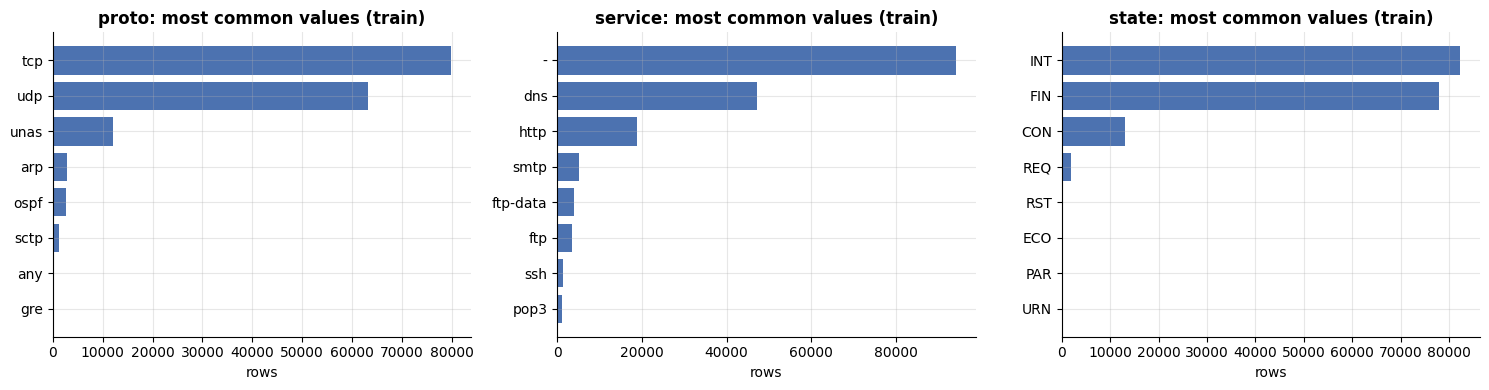

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, CATEGORICAL):
    top = train[col].value_counts().head(8)
    ax.barh(top.index[::-1], top.values[::-1], color='#4C72B0')
    ax.set(title=f'{col}: most common values (train)', xlabel='rows')
plt.tight_layout(); save_figure(fig, '01_text_columns'); plt.show()

**What we see:**

- Most flows are `tcp` or `udp`, but `proto` has more than 100 rare values.
- **More than half of the rows have `service = '-'`**. This is not a missing value; it means the service was not identified.
  We will keep it as its own category.
- The test file has two connection states that never appear in training (`ACC`, `CLO`). Our preprocessing must handle **unseen values** safely.

## 8. The number columns: ranges, zeros and long tails

Network measurements are often **skewed**: most flows are small, a few are huge. We check how many values are zero, how big the
largest values are, and how skewed each column is (skewness above 5 means a very long right tail).

In [11]:
num_summary = pd.DataFrame({
    'min': train[numeric].min(),
    'median': train[numeric].median(),
    'max': train[numeric].max(),
    '% zeros': (train[numeric] == 0).mean() * 100,
    'skewness': train[numeric].skew(),
}).sort_values('skewness', ascending=False)
save_table(num_summary, '01_numeric_summary_train', index=True)
display(num_summary.head(15))
print(f"{(num_summary.skewness > 5).sum()} of {len(numeric)} number columns have skewness above 5.")

,min,median,max,% zeros,skewness
trans_depth,0.0000,0.0000,172.0000,89.8255,167.3358
response_body_len,0.0000,0.0000,"6,558,056.0000",93.5588,76.3401
sbytes,28.0000,430.0000,"12,965,233.0000",0.0000,45.3034
sloss,0.0000,0.0000,"4,803.0000",54.4356,44.7537
dloss,0.0000,0.0000,"5,484.0000",55.1137,41.3803
spkts,1.0000,2.0000,"9,616.0000",0.0000,40.2177
dbytes,0.0000,164.0000,"14,655,550.0000",48.0675,39.7609
dpkts,0.0000,2.0000,"10,974.0000",48.0675,36.7641
dinpkt,0.0000,0.0060,"56,716.8240",48.0738,29.6795
djit,0.0000,0.0000,"289,388.2697",53.4633,29.5438


20 of 39 number columns have skewness above 5.


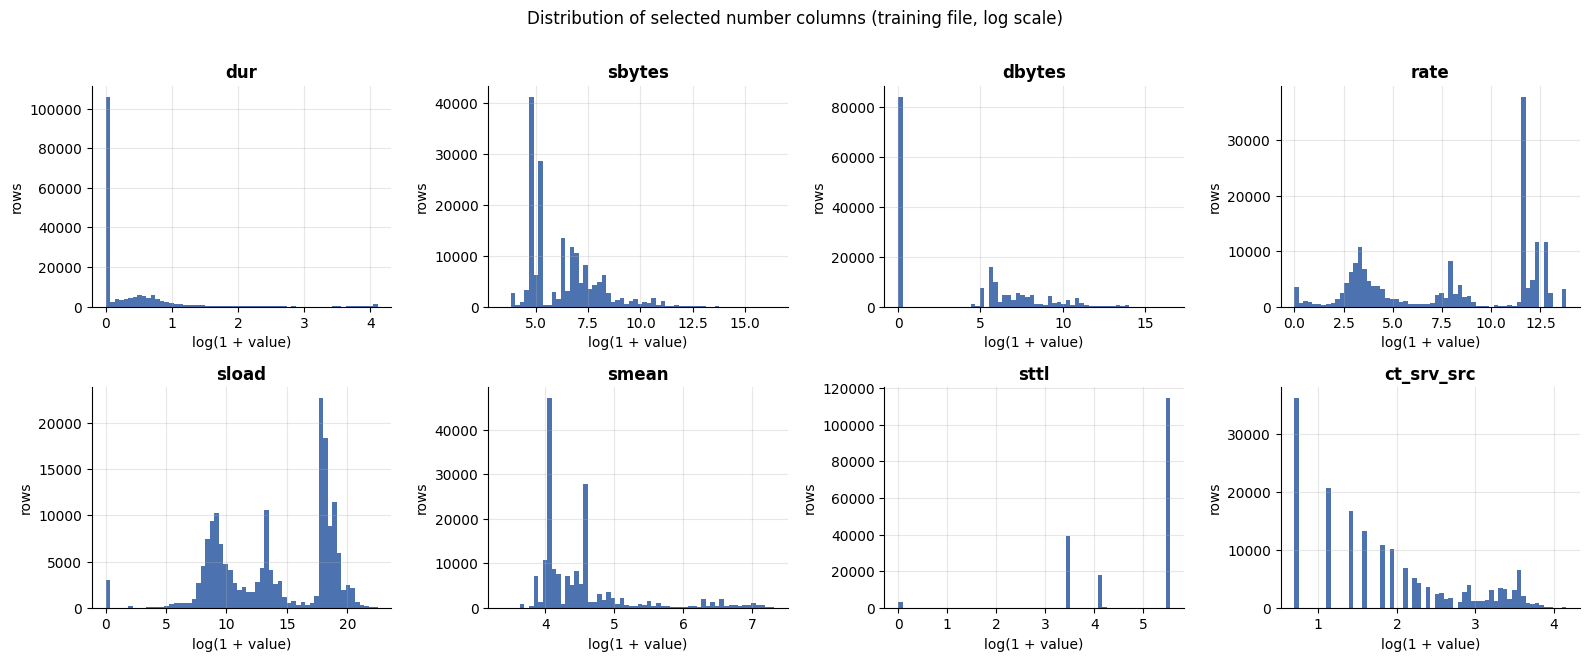

In [12]:
show = ['dur', 'sbytes', 'dbytes', 'rate', 'sload', 'smean', 'sttl', 'ct_srv_src']
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), show):
    ax.hist(np.log1p(train[col]), bins=60, color='#4C72B0')
    ax.set(title=col, xlabel='log(1 + value)', ylabel='rows')
fig.suptitle('Distribution of selected number columns (training file, log scale)', y=1.01)
plt.tight_layout(); save_figure(fig, '01_numeric_distributions'); plt.show()

**What we see:**

- Many columns are heavily skewed (for example `sload` goes up to about 6 billion bits per second while the median is far smaller).
- Many columns are **zero most of the time** (e.g. the TCP timing columns are zero for non-TCP traffic).
- Even on a log scale, several columns show separate "bumps". This suggests different kinds of traffic, which is good news for classification.
- `sttl` takes only a few distinct values. TTL is set by the sending computer's operating system, so it can act as a fingerprint of the
  machines in this testbed. It may be a very strong but **dataset-specific** signal.

These are real measurements, so we do **not** delete large values as "outliers". In Notebook 03 we will use a log transform for models that need it.

## 9. Do the training and testing files look alike?

A model learns from the training file and is judged on the testing file. If the two look very different, test scores may surprise us.
We compare the class shares (done above) and the average of each number column on a log scale.

,difference (in standard deviations)
ct_dst_src_ltm,-0.1821
tcprtt,0.1533
synack,0.1513
ackdat,0.1364
swin,0.1353
dttl,0.1175
ct_dst_sport_ltm,-0.1166
stcpb,0.1050
dwin,0.1045
dtcpb,0.1040


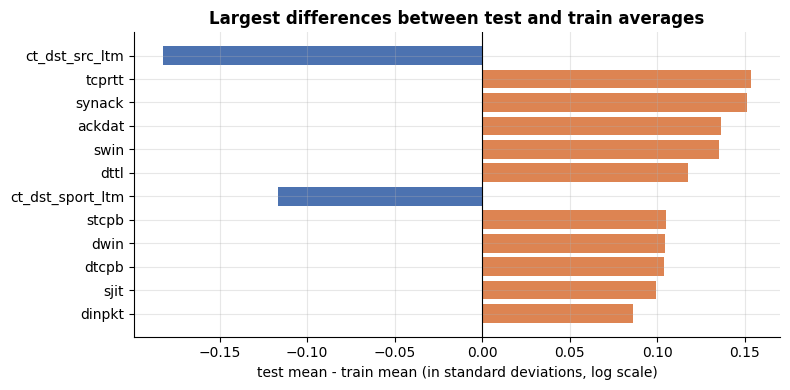

In [13]:
log_train, log_test = np.log1p(train[numeric]), np.log1p(test[numeric])
pooled_sd = np.sqrt((log_train.var() + log_test.var()) / 2).replace(0, np.nan)
shift = ((log_test.mean() - log_train.mean()) / pooled_sd).rename('difference (in standard deviations)')
shift = shift.reindex(shift.abs().sort_values(ascending=False).index).to_frame()
save_table(shift, '01_train_test_shift', index=True)
display(shift.head(10))

fig, ax = plt.subplots(figsize=(8, 4))
top = shift.head(12).iloc[::-1]
ax.barh(top.index, top.iloc[:, 0], color=np.where(top.iloc[:, 0] > 0, '#DD8452', '#4C72B0'))
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Largest differences between test and train averages', xlabel='test mean - train mean (in standard deviations, log scale)')
plt.tight_layout(); save_figure(fig, '01_train_test_shift'); plt.show()

**What we see:** The averages are close: every column differs by less than 0.2 standard deviations. The biggest shifts are in
TCP timing and window columns and in some "recent flows" counters, which fits the test file's larger share of Normal traffic
(45% instead of 32%). So the two files describe similar traffic, but the class mix is different, and test scores can still differ
from what we see during development.

## 10. Repeated rows

If we ignore `id`, how often does the exact same flow description appear more than once? Repeats matter because a model can
"memorise" a repeated row and look better than it really is. We only count them here; Notebook 02 studies them in detail.

In [14]:
def repeats(frame):
    no_id = frame.drop(columns='id')
    return {'rows': len(frame),
            'repeated rows (ignoring id)': int(no_id.duplicated().sum()),
            'repeated rows (ignoring id and both targets)': int(frame[predictors].duplicated().sum())}

repeat_table = pd.DataFrame([repeats(train), repeats(test)], index=['training', 'testing'])
repeat_table['share of rows that repeat an earlier row %'] = repeat_table.iloc[:, 2] / repeat_table.rows * 100
save_table(repeat_table, '01_repeated_rows', index=True)
display(repeat_table)

,rows,repeated rows (ignoring id),repeated rows (ignoring id and both targets),share of rows that repeat an earlier row %
training,175341,67601,74301,42.3751
testing,82332,26387,28386,34.4775


**What we see:** About **42% of training rows** repeat an earlier row's 42 predictor values exactly. Some of these repeats even have
**different labels**, which means the measurements alone cannot always tell the classes apart. This is the main topic of Notebook 02.

## 11. Columns we must never use as inputs

**Leakage** means giving the model information it would not have in real life, for example the answer itself.

- `label` and `attack_cat` are the answers, so they can never be inputs.
- `id` looks harmless, but the rows are stored **sorted by class**. The plot shows this: the class changes in large blocks as `id` grows.
  A model given `id` would learn the file order, not network behaviour. We therefore exclude `id`, and we do **not** treat it as time.

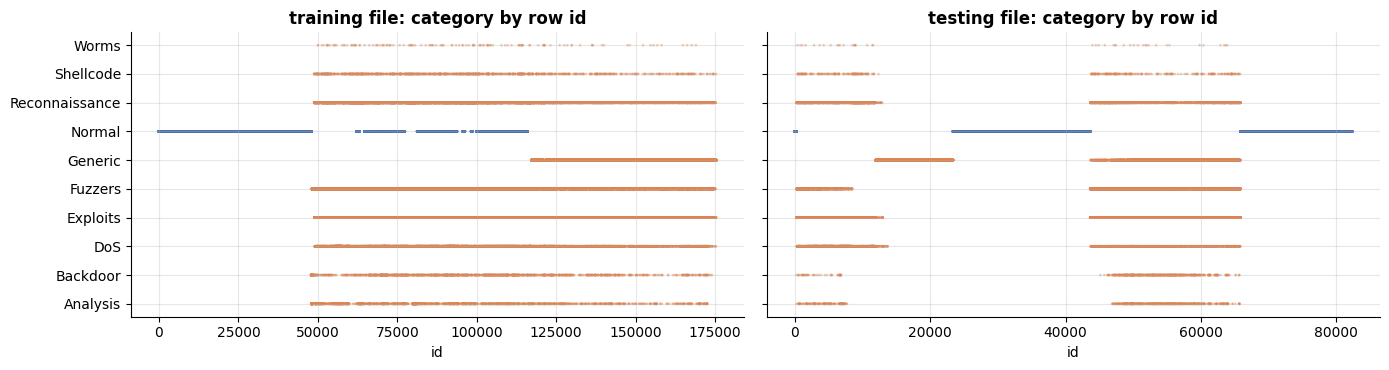

Spearman correlation between id and label: train 0.727, test -0.387


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
order = {c: i for i, c in enumerate(CLASSES)}
for ax, (name, frame) in zip(axes, [('training', train), ('testing', test)]):
    ax.scatter(frame.id, frame.attack_cat.map(order), s=1, alpha=0.3, c=frame.label.map({0: '#4C72B0', 1: '#DD8452'}))
    ax.set(title=f'{name} file: category by row id', xlabel='id')
axes[0].set_yticks(range(len(CLASSES)), CLASSES)
plt.tight_layout(); save_figure(fig, '01_category_by_id'); plt.show()

print('Spearman correlation between id and label: train %.3f, test %.3f'
      % (train[['id', 'label']].corr('spearman').iloc[0, 1], test[['id', 'label']].corr('spearman').iloc[0, 1]))

## 12. What this dataset can and cannot tell us

The reference paper combines **network-flow** features with **DNS-query** features and uses **time windows**. We check whether
our files contain what that design needs.

In [16]:
columns = set(train.columns)
checks = pd.DataFrame([
    ('A class called "Botnet"', 'botnet' in ' '.join(train.attack_cat.str.lower().unique())),
    ('DNS query details (query, domain, qtype, entropy columns)', any(k in c for c in columns for k in ['query', 'domain', 'qtype', 'entropy'])),
    ('Timestamps (stime / ltime columns)', bool(columns & {'stime', 'ltime', 'timestamp'})),
    ('IP addresses or port numbers (srcip, dstip, sport, dsport columns)', bool(columns & {'srcip', 'dstip', 'sport', 'dsport'})),
    ('A service value "dns"', (train.service == 'dns').any()),
], columns=['what we looked for', 'present?'])
save_table(checks, '01_reference_paper_requirements')
display(checks)
print(f"Rows with service = 'dns': {(train.service == 'dns').sum():,} in training")

,what we looked for,present?
0,"A class called ""Botnet""",False
1,"DNS query details (query, domain, qtype, entro...",False
2,Timestamps (stime / ltime columns),False
3,"IP addresses or port numbers (srcip, dstip, sp...",False
4,"A service value ""dns""",True


Rows with service = 'dns': 47,294 in training


**What we see:**

- There is **no "Botnet" class**. The attack types are Analysis, Backdoor, DoS, Exploits, Fuzzers, Generic, Reconnaissance, Shellcode and Worms.
  So with this dataset we study **network attack detection in general**; "Attack" does not mean "botnet".
- There are **no DNS query details**, **no timestamps** and **no IP addresses or ports**. `service = 'dns'` only says the flow was DNS traffic;
  it is not the DNS-query data the paper uses.
- So we cannot build the paper's time windows or its DNS branch from these files. We will work with **one row per completed flow**, and say so clearly.

## 13. Confirm we changed nothing

In [17]:
assert {'train': sha256(TRAIN_CSV), 'test': sha256(TEST_CSV)} == fingerprints_before == RAW_SHA256
print('Both raw files are unchanged.')

Both raw files are unchanged.


## Summary

### What we learned

| Topic | Finding |
|---|---|
| Size | 175,341 training and 82,332 testing flows; 42 predictors (39 numbers, 3 text) |
| Quality | No missing, infinite or negative values; both files share the same columns |
| Targets | 10 categories (Normal + 9 attacks). Very unbalanced: Worms has only 130 training rows |
| Text columns | Over half of `service` values are `'-'`; the test file has states never seen in training |
| Number columns | Most are strongly skewed and often zero; large values are real, not errors |
| Repeats | About 42% of training rows repeat an earlier row's predictors, sometimes with a different label |
| Leakage | `id`, `label`, `attack_cat` must never be inputs; the file order is sorted by class |
| Scope | No Botnet class, no DNS-query data, no timestamps. This is flow-level attack detection |

### What is still uncertain

- Exactly how some columns were calculated (for example the "recent flows" counters) is not fully documented.
- Whether the test file's different class mix will lower scores.

### What Notebook 02 does next

Study the **repeated rows and conflicting labels** in detail, check overlap between the training and testing files,
and create a **fair validation split** that keeps identical rows together.